In [1]:
import os
import matplotlib.pyplot as mp
import pandas as pd
import seaborn as sb
from sklearn.cluster import KMeans
# Cargar el conjunto de datos de clientes
dataset = pd.read_csv("Mall_Customers.csv")

# Visualizar el DataFrame
dataset.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [3]:
# Seleccionar todas las filas (:) y las columnas en las posiciones 3 y 4 del DataFrame,
# convirtiendo el resultado en un arreglo bidimensional de NumPy con .values
fields = dataset.iloc[:, [3, 4]].values

# Imprimir en pantalla el arreglo numérico generado
print(fields)

[[ 15  39]
 [ 15  81]
 [ 16   6]
 [ 16  77]
 [ 17  40]
 [ 17  76]
 [ 18   6]
 [ 18  94]
 [ 19   3]
 [ 19  72]
 [ 19  14]
 [ 19  99]
 [ 20  15]
 [ 20  77]
 [ 20  13]
 [ 20  79]
 [ 21  35]
 [ 21  66]
 [ 23  29]
 [ 23  98]
 [ 24  35]
 [ 24  73]
 [ 25   5]
 [ 25  73]
 [ 28  14]
 [ 28  82]
 [ 28  32]
 [ 28  61]
 [ 29  31]
 [ 29  87]
 [ 30   4]
 [ 30  73]
 [ 33   4]
 [ 33  92]
 [ 33  14]
 [ 33  81]
 [ 34  17]
 [ 34  73]
 [ 37  26]
 [ 37  75]
 [ 38  35]
 [ 38  92]
 [ 39  36]
 [ 39  61]
 [ 39  28]
 [ 39  65]
 [ 40  55]
 [ 40  47]
 [ 40  42]
 [ 40  42]
 [ 42  52]
 [ 42  60]
 [ 43  54]
 [ 43  60]
 [ 43  45]
 [ 43  41]
 [ 44  50]
 [ 44  46]
 [ 46  51]
 [ 46  46]
 [ 46  56]
 [ 46  55]
 [ 47  52]
 [ 47  59]
 [ 48  51]
 [ 48  59]
 [ 48  50]
 [ 48  48]
 [ 48  59]
 [ 48  47]
 [ 49  55]
 [ 49  42]
 [ 50  49]
 [ 50  56]
 [ 54  47]
 [ 54  54]
 [ 54  53]
 [ 54  48]
 [ 54  52]
 [ 54  42]
 [ 54  51]
 [ 54  55]
 [ 54  41]
 [ 54  44]
 [ 54  57]
 [ 54  46]
 [ 57  58]
 [ 57  55]
 [ 58  60]
 [ 58  46]
 [ 59  55]

In [5]:
import warnings  
warnings.filterwarnings("ignore")  # Ocultar avisos/advertencias en la salida de Jupyter

In [7]:
wcss = []  # Crear lista vacía para almacenar la inercia (WCSS)

for index in range(1, 11):  # Probar de 1 a 10 clusters
  kmeans = KMeans(n_clusters=index, init="k-means++", random_state=2)  # Configurar modelo K-Means
  kmeans.fit(fields)  # Entrenar el modelo con los datos

  wcss.append(kmeans.inertia_)  # Guardar la inercia calculada

Text(0, 0.5, 'WCSS')

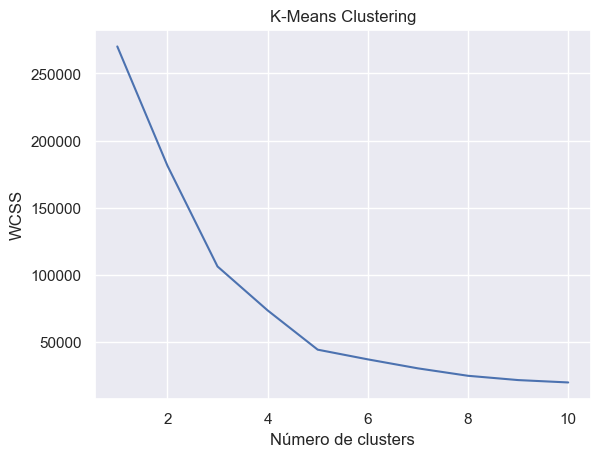

In [9]:
# Graficación del "Codo de Jambu"
sb.set()  # Aplicar estilo por defecto de seaborn
mp.plot(range(1, 11), wcss)  # Graficar WCSS contra número de clusters
mp.title("K-Means Clustering")  # Definir el título de la gráfica
mp.xlabel("Número de clusters")  # Etiquetar el eje horizontal X
mp.ylabel("WCSS")  # Weighted cluster sum of squares  # Etiquetar el eje vertical Y

In [11]:
kmeans = KMeans(n_clusters=5, init="k-means++", random_state=42)  # Configurar K-Means con 5 clusters
cluster_values = kmeans.fit_predict(fields)  # Entrenar modelo y asignar un cluster a cada dato
print(cluster_values)  # Imprimir la lista de clusters asignados

[2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2
 3 2 3 2 3 2 0 2 3 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 4 1 4 0 4 1 4 1 4 0 4 1 4 1 4 1 4 1 4 0 4 1 4 1 4
 1 4 1 4 1 4 1 4 1 4 1 4 1 4 1 4 1 4 1 4 1 4 1 4 1 4 1 4 1 4 1 4 1 4 1 4 1
 4 1 4 1 4 1 4 1 4 1 4 1 4 1 4]


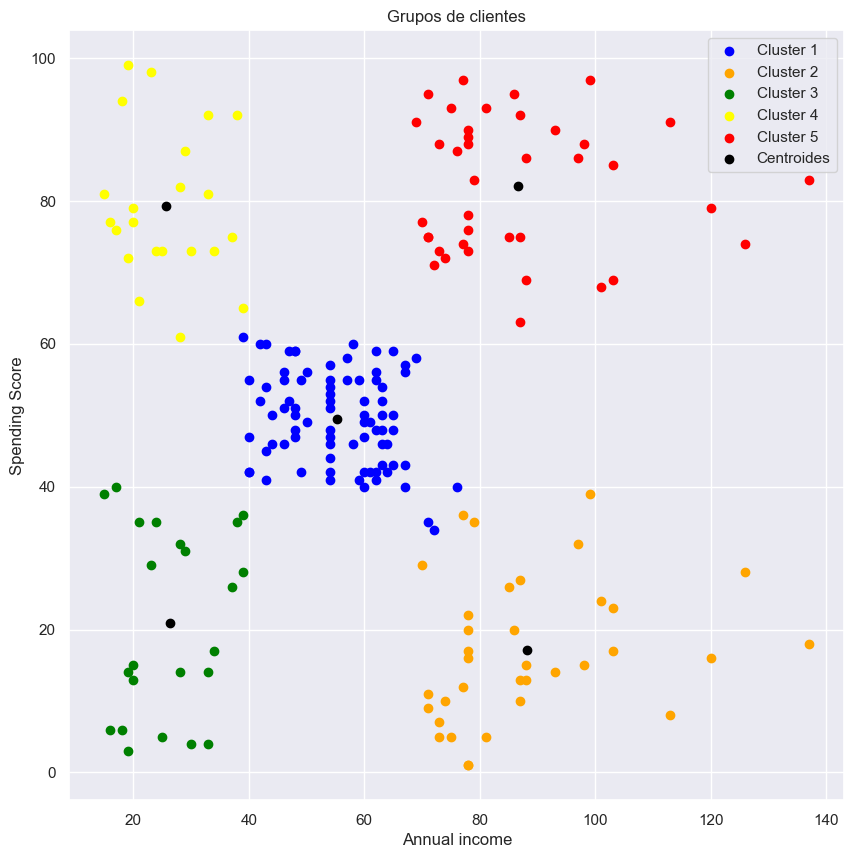

In [13]:
mp.figure(figsize=(10, 10))  # Definir tamaño del lienzo de la gráfica (10x10)
mp.scatter(fields[cluster_values == 0, 0], fields[cluster_values == 0, 1], c='blue', label='Cluster 1')  # Graficar los puntos del Cluster 1 
mp.scatter(fields[cluster_values == 1, 0], fields[cluster_values == 1, 1], c='orange', label='Cluster 2')  # Graficar los puntos del Cluster 2 
mp.scatter(fields[cluster_values == 2, 0], fields[cluster_values == 2, 1], c='green', label='Cluster 3')  # Graficar los puntos del Cluster 3 
mp.scatter(fields[cluster_values == 3, 0], fields[cluster_values == 3, 1], c='yellow', label='Cluster 4')  # Graficar los puntos del Cluster 4 
mp.scatter(fields[cluster_values == 4, 0], fields[cluster_values == 4, 1], c='red', label='Cluster 5')  # Graficar los puntos del Cluster 5 

mp.scatter(kmeans.cluster_centers_[:,0] , kmeans.cluster_centers_[:,1] , c='black', label= 'Centroides' )
 
mp.title("Grupos de clientes")  # Agregar título a la gráfica
mp.xlabel("Annual income")  # Etiquetar el eje X
mp.ylabel("Spending Score")  # Etiquetar el eje Y
mp.legend()  # Mostrar leyenda

In [15]:
# Criterio de Silueta ("Silhouette")
from sklearn import datasets 
from sklearn.metrics import silhouette_score  

In [17]:
X = dataset.iloc[:, [3, 4]].to_numpy()  # Convertir columnas 3 y 4 en arreglo NumPy
for j in range(2, 12):  # Probar de 2 a 11 clusters
  kmeans = KMeans(n_clusters=j, random_state=42)  # Configurar K-Means
  kmeans.fit_predict(X)  # Ajustar y predecir asignaciones de clusters
  # Calculamos el Score de Silueta
  score = silhouette_score(X, kmeans.labels_, metric='euclidean')  # Calcular el coeficiente de silueta
  print("Score Silhouette;", "k = ", j, ":", score)  # Imprimir resultado del score

Score Silhouette; k =  2 : 0.2968969162503008
Score Silhouette; k =  3 : 0.46761358158775435
Score Silhouette; k =  4 : 0.4931963109249047
Score Silhouette; k =  5 : 0.553931997444648
Score Silhouette; k =  6 : 0.53976103063432
Score Silhouette; k =  7 : 0.5264283703685728
Score Silhouette; k =  8 : 0.45827056882053113
Score Silhouette; k =  9 : 0.4553729779390266
Score Silhouette; k =  10 : 0.45925273534781125
Score Silhouette; k =  11 : 0.43844724497454024


In [19]:
# Algoritmo KMeans aplicado a 3 columnas de nuestra base original
# bajo una transformación de PCA

fields2 = dataset.iloc[:, [2, 3, 4]].values  
print(fields2)  

[[ 19  15  39]
 [ 21  15  81]
 [ 20  16   6]
 [ 23  16  77]
 [ 31  17  40]
 [ 22  17  76]
 [ 35  18   6]
 [ 23  18  94]
 [ 64  19   3]
 [ 30  19  72]
 [ 67  19  14]
 [ 35  19  99]
 [ 58  20  15]
 [ 24  20  77]
 [ 37  20  13]
 [ 22  20  79]
 [ 35  21  35]
 [ 20  21  66]
 [ 52  23  29]
 [ 35  23  98]
 [ 35  24  35]
 [ 25  24  73]
 [ 46  25   5]
 [ 31  25  73]
 [ 54  28  14]
 [ 29  28  82]
 [ 45  28  32]
 [ 35  28  61]
 [ 40  29  31]
 [ 23  29  87]
 [ 60  30   4]
 [ 21  30  73]
 [ 53  33   4]
 [ 18  33  92]
 [ 49  33  14]
 [ 21  33  81]
 [ 42  34  17]
 [ 30  34  73]
 [ 36  37  26]
 [ 20  37  75]
 [ 65  38  35]
 [ 24  38  92]
 [ 48  39  36]
 [ 31  39  61]
 [ 49  39  28]
 [ 24  39  65]
 [ 50  40  55]
 [ 27  40  47]
 [ 29  40  42]
 [ 31  40  42]
 [ 49  42  52]
 [ 33  42  60]
 [ 31  43  54]
 [ 59  43  60]
 [ 50  43  45]
 [ 47  43  41]
 [ 51  44  50]
 [ 69  44  46]
 [ 27  46  51]
 [ 53  46  46]
 [ 70  46  56]
 [ 19  46  55]
 [ 67  47  52]
 [ 54  47  59]
 [ 63  48  51]
 [ 18  48  59]
 [ 43  48 

In [21]:
from sklearn import decomposition  # Importar módulo de reducción de dimensionalidad

pca = decomposition.PCA(n_components=2)  # Configurar PCA a 2 componentes
pca.fit(fields2)  # Ajustar el modelo con los datos
fields2 = pca.transform(fields2)  # Reducir los datos a 2 dimensiones
fields2  # Mostrar matriz resultante

array([[-3.18705078e+01, -3.30014253e+01],
       [ 7.63396908e-01, -5.68438653e+01],
       [-5.74087256e+01, -1.31229362e+01],
       [-2.16989648e+00, -5.34779049e+01],
       [-3.21749197e+01, -3.03870050e+01],
       [-2.17827777e+00, -5.22265808e+01],
       [-5.90660565e+01, -9.54170669e+00],
       [ 1.23693261e+01, -6.16176843e+01],
       [-6.63156568e+01, -3.21359934e+00],
       [-5.65677534e+00, -4.72664534e+01],
       [-5.82366179e+01, -9.13375312e+00],
       [ 1.46202592e+01, -6.21072940e+01],
       [-5.51612126e+01, -1.00779778e+01],
       [-4.30660584e-03, -5.01134367e+01],
       [-5.27647474e+01, -1.16804199e+01],
       [ 1.94563480e+00, -5.15231943e+01],
       [-3.45062349e+01, -2.37600734e+01],
       [-7.30573032e+00, -4.35158724e+01],
       [-4.12574933e+01, -1.64734320e+01],
       [ 1.61888268e+01, -5.82998775e+01],
       [-3.27403118e+01, -2.13349462e+01],
       [-9.82702739e-01, -4.44533143e+01],
       [-5.78102821e+01, -1.86854579e+00],
       [-1.

In [23]:
wcss2 = []  # Crear lista vacía para almacenar inercia

for index in range(1, 11):  # Probar de 1 a 10 clusters
    kmeans = KMeans(n_clusters = index, init = "k-means++", random_state = 2)  # Configurar K-Means
    kmeans.fit(fields2)  # Entrenar modelo con datos transformados
    
    wcss2.append(kmeans.inertia_)  # Guardar inercia calculada

Text(0, 0.5, 'WCSS')

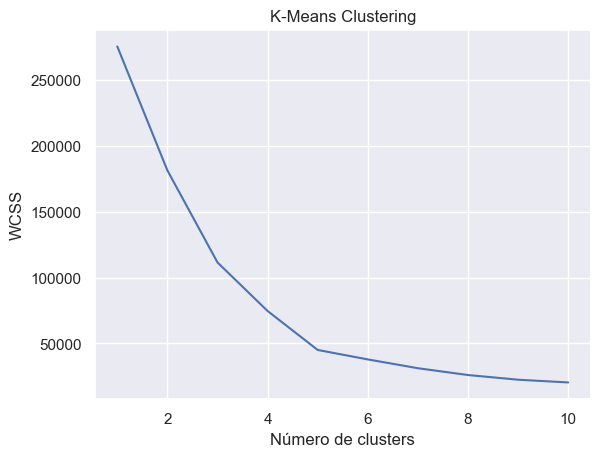

In [25]:
# Graficación del "Codo de Jambu"
sb.set()  # Estilo de seaborn
mp.plot(range(1, 11), wcss2)  # Graficar WCSS2 contra número de clusters
mp.title("K-Means Clustering")  # Título de la gráfica
mp.xlabel("Número de clusters")  # Etiqueta eje X
mp.ylabel("WCSS")  # Weighted cluster sum of squares  # Etiqueta eje Y

In [27]:
kmeans = KMeans(n_clusters = 5, init = "k-means++", random_state = 42)  # Configurar modelo KMeans
cluster_values = kmeans.fit_predict(fields2)  # Asignar clusters a los datos transformados
print(cluster_values)  # Imprimir asignación de clusters

[2 4 2 4 2 4 2 4 2 4 2 4 2 4 2 4 2 4 2 4 2 4 2 4 2 4 2 4 2 4 2 4 2 4 2 4 2
 4 2 4 2 4 2 0 2 4 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 1 0 1 0 1 3 1 3 1 0 1 3 1 3 1 3 1 3 1 0 1 3 1 3 1
 3 1 3 1 3 1 3 1 3 1 3 1 3 1 3 1 3 1 3 1 3 1 3 1 3 1 3 1 3 1 3 1 3 1 3 1 3
 1 3 1 3 1 3 1 3 1 3 1 3 1 3 1]


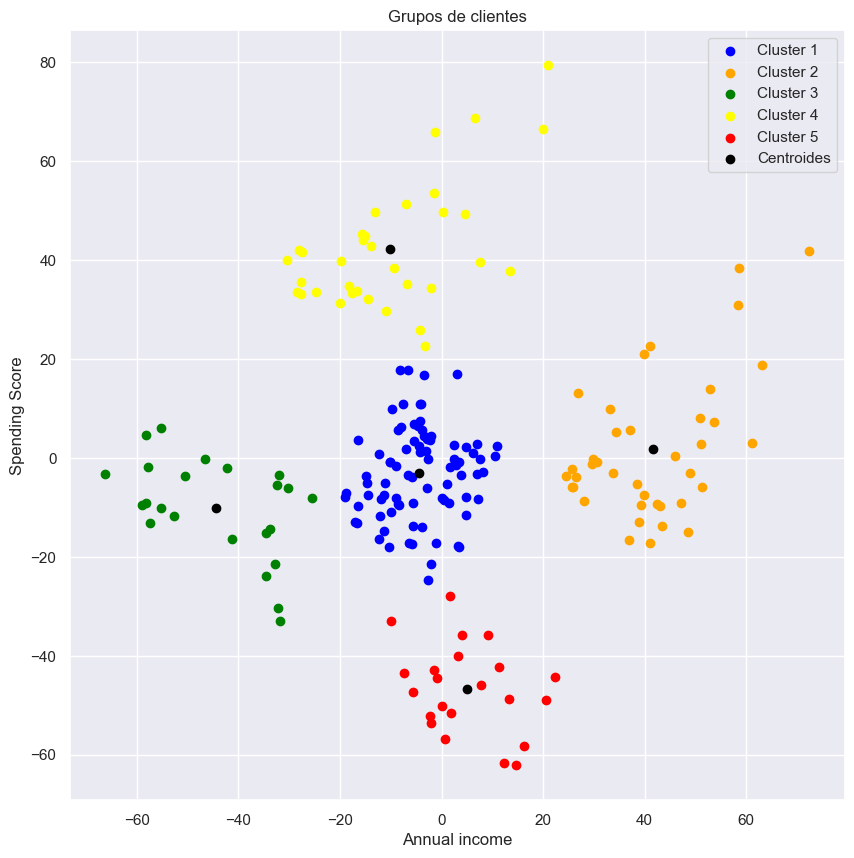

In [29]:
mp.figure(figsize =(10,10))  # Definir tamaño de la figura

mp.scatter(fields2[cluster_values==0,0], fields2[cluster_values==0,1], c = 'blue', label = 'Cluster 1')  # Graficar Cluster 1
mp.scatter(fields2[cluster_values==1,0], fields2[cluster_values==1,1], c = 'orange', label = 'Cluster 2')  # Graficar Cluster 2
mp.scatter(fields2[cluster_values==2,0], fields2[cluster_values==2,1], c = 'green', label = 'Cluster 3')  # Graficar Cluster 3
mp.scatter(fields2[cluster_values==3,0], fields2[cluster_values==3,1], c = 'yellow', label = 'Cluster 4')  # Graficar Cluster 4
mp.scatter(fields2[cluster_values==4,0], fields2[cluster_values==4,1], c = 'red', label = 'Cluster 5')  # Graficar Cluster 5

mp.scatter(kmeans.cluster_centers_[:,0],kmeans.cluster_centers_[:,1], c = 'black', label = 'Centroides')  # Graficar centroides de cada cluster

mp.title("Grupos de clientes")  # Definir título
mp.xlabel("Annual income")  # Etiqueta eje X
mp.ylabel("Spending Score")  # Etiqueta eje Y
mp.legend()  # Mostrar leyenda